# Análisis de resultados de búsquedas de ConceptNet

El objetivo es poder hacer un conteo de los conceptos y las relaciones que se encuentran en los caminos obtenidos de ConceptNet, así como revisar y analizar el conjunto de datos del meta-análisis de las correlaciones entre emociones y situaciones de Appraisal

In [ ]:
#Importes

import csv
import seaborn as sns
import pandas as pd
import pickle 
from collections import Counter
import pandas as pd

from matplotlib import pyplot as plt

## Conteo de relaciones y conceptos en caminos

___

### Análisis de caminos entre Felicidad Altamente Prototípicas a Tristeza Altamente Prototípicas. Relaciones: Implicatura (sin sinonimia) 

In [ ]:
# Carga de datos de trabajo

with open("caminos_obtenidos/fA_tA_implicatura2_21112026.pickle", "rb") as f:
    caminosFaT = pickle.load(f)


with open("data/meta-analysis_data.csv", encoding= 'latin1') as f:
    df = pd.read_csv(f)

candidatos_ing = []

with open('puentes_candidatos/Candidatos_puentes_ingles_noSinonimia_FA_TA.csv', 'r') as f:
   reader = csv.reader(f)
   for row in reader:
       candidatos_ing.append(row[0])

In [25]:
len(caminosFaT)

5144

In [24]:
caminosFaT

{('admiration',
  'depressed'): ['admiration <--HasSubevent-- go_to_performance (en) --HasSubevent--> have_fun (en) <--HasSubevent-- eat_ice_cream (en) --MotivatedByGoal--> depressed (en)', 'admiration <--HasSubevent-- go_to_performance (en) --HasPrerequisite--> drive_to_theatre (en) <--HasPrerequisite-- watch_film (en) --HasSubevent--> eat_ice_cream (en) --MotivatedByGoal--> depressed (en)', 'admiration <--Causes-- watching_musician_perform (en) --HasSubevent--> fall_asleep (en) <--HasLastSubevent-- drink_too_much (en) <--HasSubevent-- hit_bottle (en) --MotivatedByGoal--> depressed (en)', 'admiration <--HasSubevent-- go_to_performance (en) --HasSubevent--> fall_asleep (en) <--HasLastSubevent-- drink_too_much (en) <--HasSubevent-- hit_bottle (en) --MotivatedByGoal--> depressed (en)', 'admiration <--HasSubevent-- go_to_performance (en) --HasLastSubevent--> leave_theater (en) <--HasLastSubevent-- watch_film (en) --HasSubevent--> eat_ice_cream (en) --MotivatedByGoal--> depressed (en)', 'a

#### Definición de funciones

In [ ]:
# Funciones necesarias para el trabajo de análisis
"""Toma el diccionario con los caminos obtenidos, y regresa dos diccionarios
Uno con el conteo de los conceptos en el camino, y otro con el conteo de relaciones
Excluye las relaciones de sinonimia para traducir los términos al inglés """

def contador(caminos:dict)-> dict:
    tokens = []
    relaciones = []
    caminos_completos = []
    for _, v in caminos.items():
        for w in v:
            caminos_completos.append(w)

    total = len(caminos_completos)
    print(f'Total de caminos: {total}')
    for camino in caminos_completos:
        camino = camino.split(' ')
        for w in camino[1:-1]:
            if w not in '(en) (es)':
                if w[0] not in '- <':
                    tokens.append(w)
                else:
                    relaciones.append(w)

    tokens_conteos = Counter(tokens)
    relaciones_conteos = Counter(relaciones)
    
    return tokens_conteos, relaciones_conteos

def guardarConteos(conteos:dict, nombre:str)->None:
    with open(f'puentes_candidatos/{nombre}', 'wb') as f:
        pickle.dump(conteos, f, protocol=pickle.HIGHEST_PROTOCOL)

"""
#################################################################################################################################
Función para graficar la distribución log log, la distribución y las top n palabras más frecuentes.
Sirve para las palabras, así como para las relaciones y las tuplas de relaciones inmediatas para las palabras y las palabras a 
las que éstas están relacionadas
#################################################################################################################################

"""

def graficador(datos:list, idioma:str, top_n:int) -> list:
    temp = {}
    for k in datos.keys():
       if type(k) == type(''):
           break
       else:
           temp[' '.join(k)] = datos[k]
    if temp:
        datos = temp

    ordenadas = sorted(datos.items(), key = lambda x: x[1], reverse=True)
    frecuencias = [frec for p,frec in ordenadas]
    rank = range(1, len(frecuencias) + 1)
    plt.figure(figsize=(9,5))
    plt.plot(rank, frecuencias, color='r')

    plt.yscale('log')
    plt.xscale('log')
    plt.xlabel('Rangos de palabras (Log)')
    plt.ylabel('Frecuencias (Log)')
    plt.title(f'Distribución de Frecuencias (Ley Zipf){idioma}')
    plt.grid(True, which='both', linestyle = '--', alpha = 0.5)
    plt.show()

    plt.figure(figsize=(9,5))
    sns.histplot(frecuencias, bins= 50, kde=True, color='teal')
    plt.xlabel('Frecuencia de la palabra')
    plt.ylabel('Cantidad de palabras')
    plt.title(f'Distribución de Frecuencias en caminos en {idioma}')
    plt.show()
    
    top_w = ordenadas[:top_n]

    p, f = zip(*top_w)

    plt.figure(figsize=(13, 10))
    sns.barplot(x=list(f), y=list(p), hue=list(p), palette='viridis', legend=False)
    plt.xlabel('Frecuencia')
    plt.ylabel('Palabra')
    plt.title(f'Top {top_n} palabras más frecuentes en {idioma}')
    plt.show()

    return top_w

"""
#################################################################################################################################
Función para recuperar los caminos que contienen las palabras no emocionales más frecuentes. A partir de los caminos recuperados
y de las palabras candidatas filtradas para excluir conceptos emocionales, esta función crea un diccionario en el que sólo
almacena los los caminos que contienen alguna de las palabras no emocionales. Las guarda con k igual al par de palabras
del diccionario de caminos
#################################################################################################################################

"""

def recuperaCaminos(caminosCompletos:dict, candidatos:tuple)-> dict:
    caminos_candidatos_puentes = {}
    for k in caminosCompletos.keys():
        for camino in caminosCompletos[k]:
            l = []
            camino = camino.split(' ')
            for c in camino:
                if c in candidatos:
                    l.append(camino)
            if len(l) > 0:
                caminos_candidatos_puentes[k] = l
    print(f'Pares de palabras recuperados: {len(caminos_candidatos_puentes)}')
    return caminos_candidatos_puentes


"""
#################################################################################################################################
Función para asegurar que no haya caminos repetidos por cada key del diccionario
#################################################################################################################################
"""


def eliminaRepeticion(caminos: dict)->dict:
    for v in caminos.values():
        index = set({})
        if len(v)>1:
            for i in range(len(v)-1):
                for j in range(len(v)-i-1):
                    if v[i] == v[j+i+1]:
                        index.add(i)
    if len(index) > 0:
        listaI = list(index)
        listaI.reverse()
        for i in listaI:
            v.pop(i)
    index.clear()

    return caminos


"""
#################################################################################################################################
Función para dividir los caminos de acuerdo a las direcciones de sus relaciones. Regresa tres listas de listas, una con los 
caminos que sólo tienen relaciones de izquierda a derecha, otra con relaciones de derecha a izquierda y una con caminos en
ambas direcciones
#################################################################################################################################
"""


def agrupadorDireccion(caminos: dict)->list:
    caminos_izquierda = []
    caminos_derecha = []
    caminos_mixtos = []
    for v in caminos.values():
        for camino in v:
            derecha = False
            izquierda = False 
            for p in camino[1:-1]:           
                if p[0] == '<':
                    izquierda = True
                elif p[-1] == '>':
                    derecha = True
            if izquierda == True and derecha == True:
                caminos_mixtos.append(camino)
            elif izquierda==True and derecha == False:
                caminos_izquierda.append(camino)
            elif izquierda == False and derecha == True:
                caminos_derecha.append(camino)

    print(f'Caminos hacia la izquierda: {len(caminos_izquierda)}')
    print(f'Caminos hacia la derecha: {len(caminos_derecha)}')
    print(f'Caminos mixtos: {len(caminos_mixtos)}')

    return caminos_izquierda, caminos_derecha, caminos_mixtos


"""
#################################################################################################################################
Función para obtener los vecinos de los términos más comunes excluyendo las palabras emoicionales. Regresa 5 listas, una con la
palabra del top n, su relación a la izquierda, la palabra a la que se relaciona, la relación a la derecha y la palabra a la que 
se relaciona. Las siguientes dos son las listas con la palabra y la relación y el concepto al que se relaciona a la izquierda y a 
la derecha respectivamente. Las últimas 2 son sólo las relaciones a la izquierda y ala deracha junto con la palabra.
#################################################################################################################################
"""


def getVecions(caminos: dict, candidatas: tuple)->list:
    vecions_todos_top50 = []
    vecinos_izquierda_top50 = []
    vecinos_derecha_top50 = []
    relacion_izquierda_top50 = []
    relacion_derecha_top50 = []
    for v in caminos.values():
        for i in range(len(v[0])):
            if v[0][i] in candidatas:
                if v[0][i-3] == '(en)' and v[0][i+3]=='(en)':
                    vecions_todos_top50.append(' '.join((v[0][i-4], v[0][i-1], v[0][i], v[0][i+2], v[0][i+4])))
                    vecinos_izquierda_top50.append((v[0][i-4], v[0][i-1], v[0][i]))
                    vecinos_derecha_top50.append((v[0][i], v[0][i+2], v[0][i+4]))
                elif v[0][i-3]=='(en)' and v[0][i+3]!='(en)':
                    vecions_todos_top50.append((v[0][i-4], v[0][i-1], v[0][i], v[0][i+2], v[0][i+3]))
                    vecinos_izquierda_top50.append((v[0][i-4], v[0][i-1], v[0][i]))
                elif v[0][i-3] != '(en)' and v[0][i+3] == '(en)':
                    vecions_todos_top50.append((v[0][i-3], v[0][i-1], v[0][i], v[0][i+2], v[0][i+4]))
                    vecinos_derecha_top50.append((v[0][i], v[0][i+2], v[0][i+4]))
                else:
                    vecions_todos_top50.append((v[0][i-3], v[0][i-1], v[0][i], v[0][i+2], v[0][i+3]))
                    vecinos_derecha_top50.append((v[0][i], v[0][i+2], v[0][i+3]))
                    vecinos_izquierda_top50.append((v[0][i-3], v[0][i-1], v[0][i]))
                    relacion_izquierda_top50.append((v[0][i-1], v[0][i]))
                    relacion_derecha_top50.append((v[0][i], v[0][i+2]))
    return vecinos_derecha_top50, vecinos_izquierda_top50, vecinos_derecha_top50, relacion_izquierda_top50, relacion_derecha_top50


#### Flujo de trabajo

In [5]:
conteos_concepts_a, conteos_relaciones_a = contador(caminosFaT)

51395


In [6]:
len(conteos_concepts_a)

4339

In [7]:
conteos_relaciones_a

Counter({'--Causes-->': 47548,
         '<--Causes--': 36618,
         '--HasSubevent-->': 32424,
         '<--HasSubevent--': 28181,
         '<--HasPrerequisite--': 25091,
         '--HasPrerequisite-->': 15253,
         '<--MotivatedByGoal--': 12706,
         '--MotivatedByGoal-->': 10344,
         '<--CausesDesire--': 7120,
         '--CausesDesire-->': 6250,
         '--HasFirstSubevent-->': 2773,
         '<--HasFirstSubevent--': 2648,
         '--Desires-->': 2328,
         '--HasLastSubevent-->': 2316,
         '<--Desires--': 2032,
         '<--HasLastSubevent--': 1699,
         '<--ReceivesAction--': 1129,
         '--ReceivesAction-->': 114,
         '--Entails-->': 50,
         '<--Entails--': 21})

In [ ]:
#Recuperación de conteos de palabras no emocionales

conteos_ing = {}

for w in candidatos_ing:
    conteos_ing[w]=conteos_concepts_a[w]




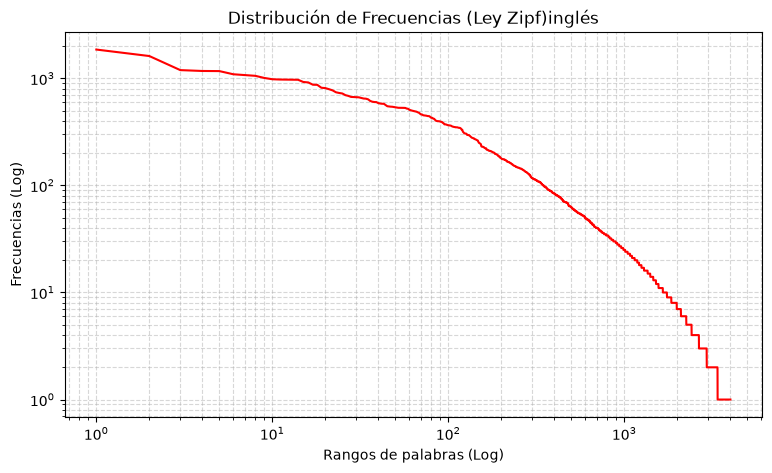

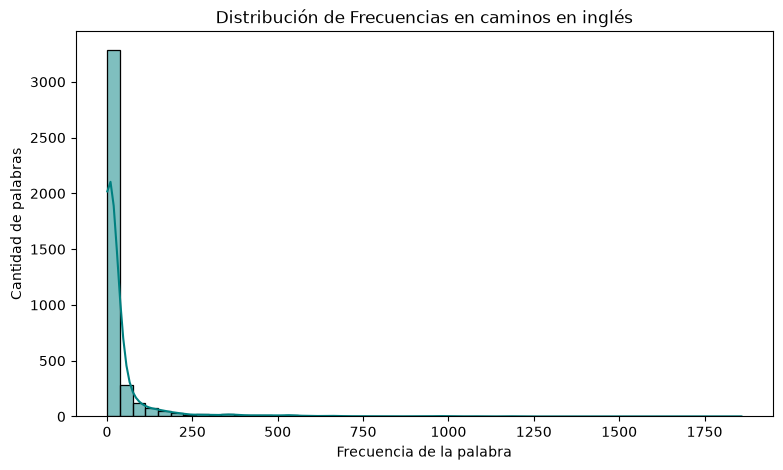

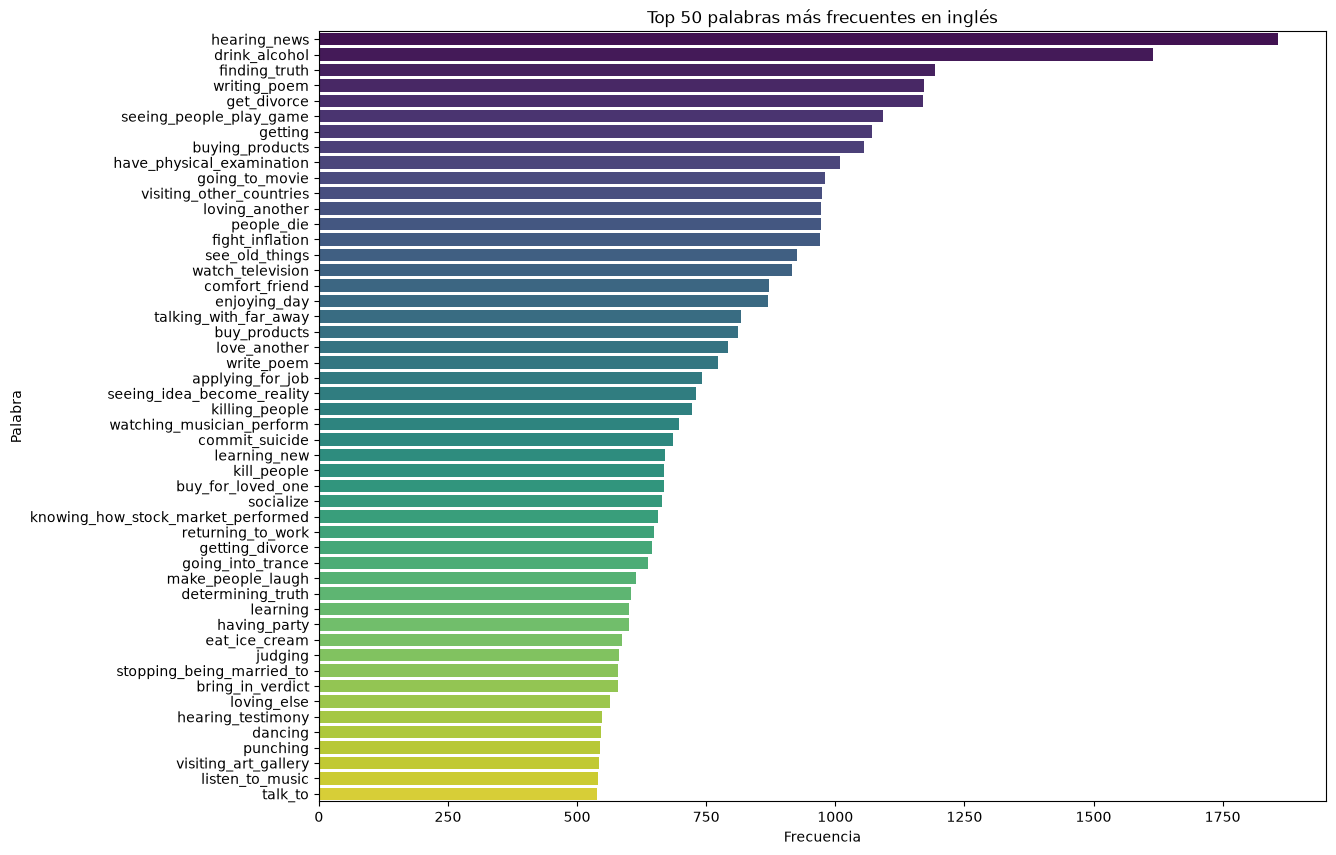

In [ ]:
top50 = graficador(conteos_ing, idioma= 'inglés', top_n= 50)

In [59]:
type(top50)

list

In [13]:
pCandidatas, c = zip(*top50)
candidatos = set(pCandidatas)

In [52]:
type(pCandidatas)

tuple

In [61]:
caminos_candidatos_puentes = recuperaCaminos(caminosCompletos=caminosFaT, candidatos=pCandidatas)

Pares de palabras recuperados: 4593


In [ ]:
caminos_candidatos_puentes= eliminaRepeticion(caminos=caminos_candidatos_puentes)

In [ ]:
caminos_izquierda, caminos_derecha, caminos_mixtos = agrupadorDireccion(caminos=caminos_candidatos_puentes)

Caminos hacia la izquierda: 10
Caminos hacia la derecha: 4
Caminos mixtos: 5579


In [19]:
caminos_izquierda

[['nice',
  '<--HasPrerequisite--',
  'talk_to',
  '(en)',
  '<--HasPrerequisite--',
  'forgive',
  '(en)',
  '<--CausesDesire--',
  'compassion',
  '(en)'],
 ['nice',
  '<--HasPrerequisite--',
  'talk_to',
  '(en)',
  '<--HasPrerequisite--',
  'make_friends',
  '(en)',
  '<--CausesDesire--',
  'loneliness',
  '(en)'],
 ['kind',
  '<--HasPrerequisite--',
  'meet_friend',
  '(en)',
  '<--CausesDesire--',
  'feeling_lonely',
  '(en)',
  '<--MotivatedByGoal--',
  'talk_to',
  '(en)',
  '<--CausesDesire--',
  'loneliness',
  '(en)'],
 ['enjoy',
  '<--MotivatedByGoal--',
  'talk_to',
  '(en)',
  '<--HasPrerequisite--',
  'forgive',
  '(en)',
  '<--CausesDesire--',
  'compassion',
  '(en)'],
 ['breathtaking',
  '<--Causes--',
  'breathing',
  '(en)',
  '<--HasSubevent--',
  'being_alive',
  '(en)',
  '<--HasPrerequisite--',
  'talking',
  '(en)',
  '<--HasSubevent--',
  'socialize',
  '(en)',
  '<--CausesDesire--',
  'loneliness',
  '(en)'],
 ['fall_in_love',
  '<--HasSubevent--',
  'meet',


In [20]:
caminos_derecha

[['love',
  '--CausesDesire-->',
  'talk_to',
  '(en)',
  '--HasPrerequisite-->',
  'think',
  '(en)',
  '--HasSubevent-->',
  'worry',
  '(en)'],
 ['fun',
  '--CausesDesire-->',
  'see_exhibits',
  '(en)',
  '--HasSubevent-->',
  'learning_new',
  '(en)',
  '--Causes-->',
  'frustration',
  '(en)'],
 ['entertaining',
  '--Causes-->',
  'embarassment',
  '(en)',
  '--CausesDesire-->',
  'go_into_coma',
  '(en)',
  '--HasLastSubevent-->',
  'dancing',
  '(en)',
  '--Causes-->',
  'humiliation',
  '(en)'],
 ['encouraging',
  '--CausesDesire-->',
  'have_party',
  '(en)',
  '--HasSubevent-->',
  'dancing',
  '(en)',
  '--HasSubevent-->',
  'falling_in_love',
  '(en)',
  '--Causes-->',
  'suffering',
  '(en)']]

In [ ]:
vecinos_todos_top50, vecinos_izquierda_top50, vecinos_derecha_top50, relacion_izquierda_top50, relacion_derecha_top50 = getVecions(
    caminos= caminos_candidatos_puentes, candidatas= pCandidatas
)

In [ ]:
conteoVecions = Counter(vecinos_todos_top50)
conteoVecionsIzquierda = Counter(vecinos_izquierda_top50)
conteoVecionsDerecha = Counter(vecinos_derecha_top50)
conteoRelacionesIzquierda = Counter(relacion_izquierda_top50)
conteoRelacionesDerecha = Counter(relacion_derecha_top50)

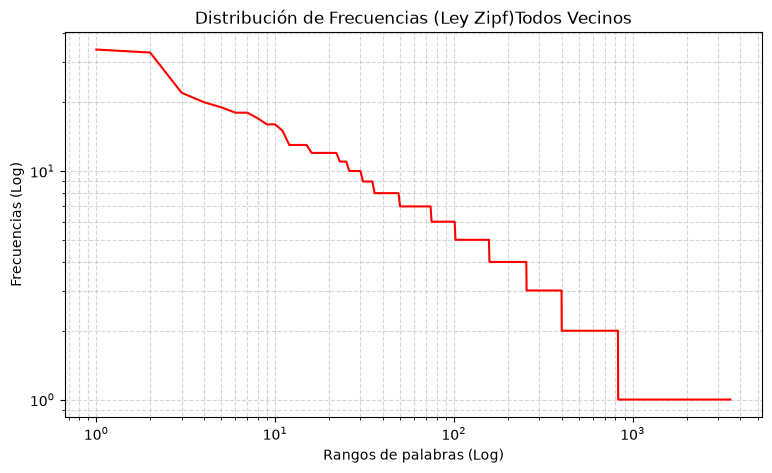

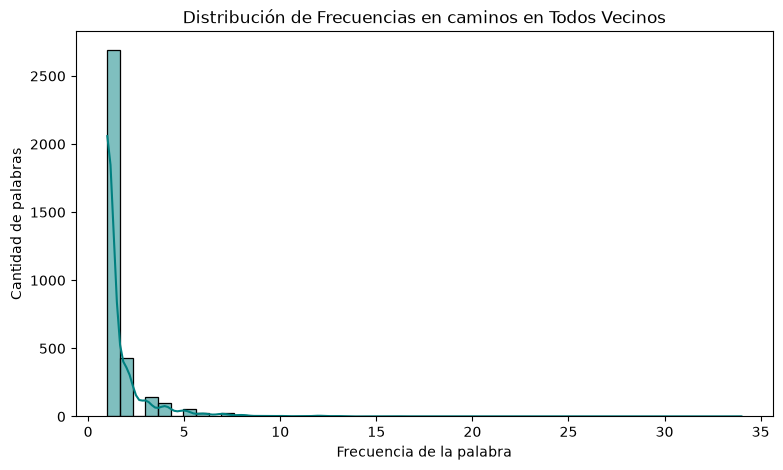

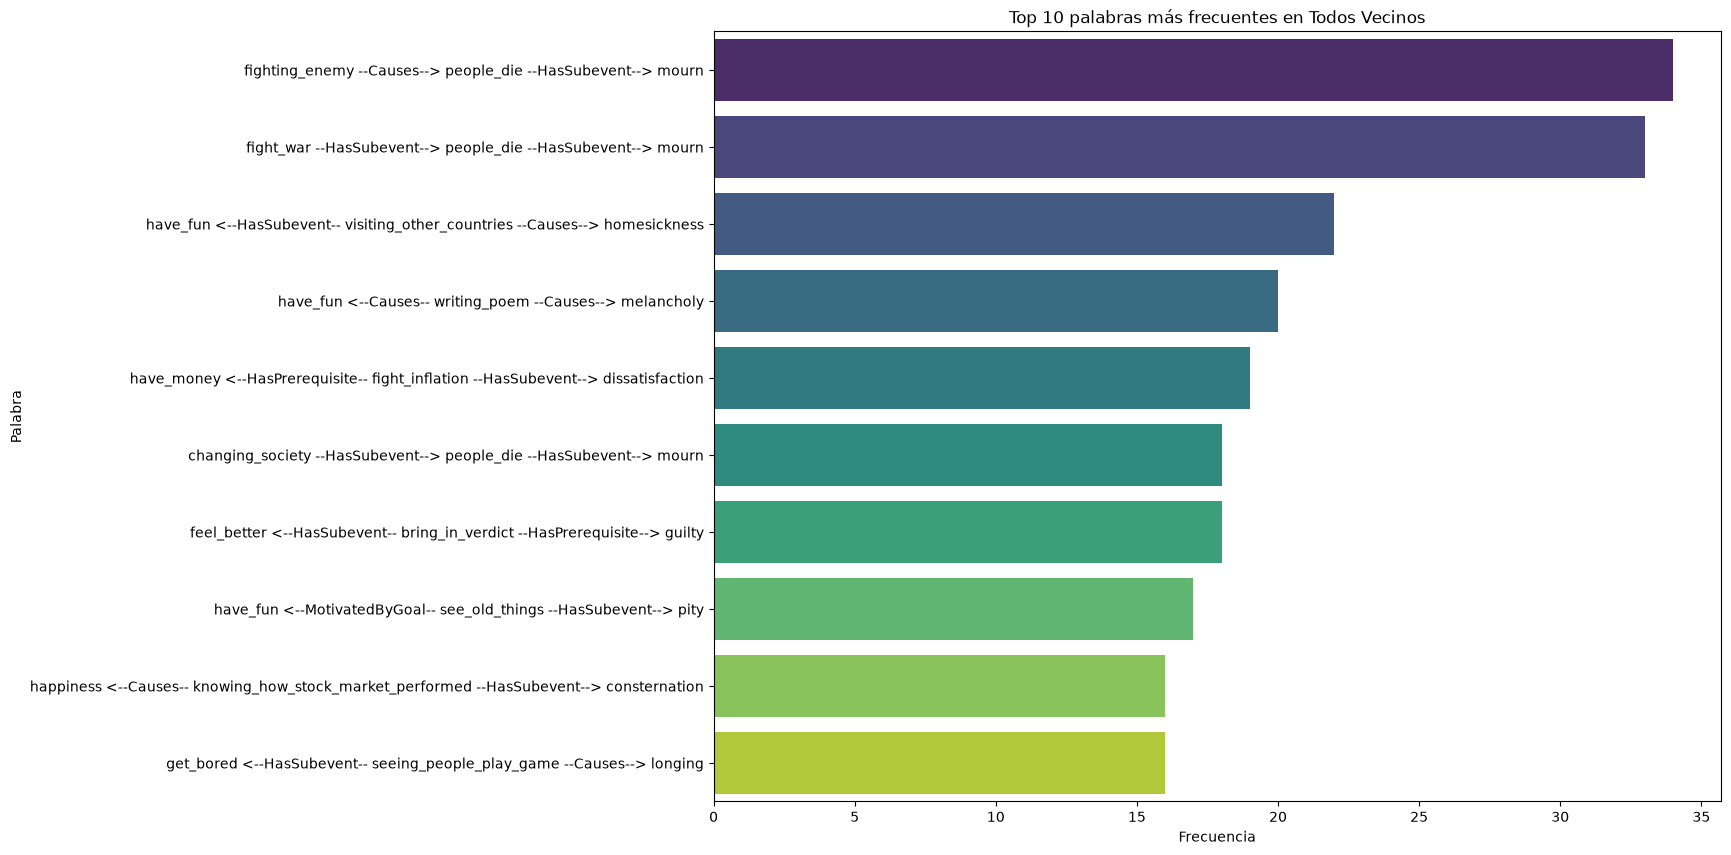

In [54]:
top10VecinosTodos = graficador(datos = conteoVecions, idioma= 'Todos Vecinos', top_n=10)

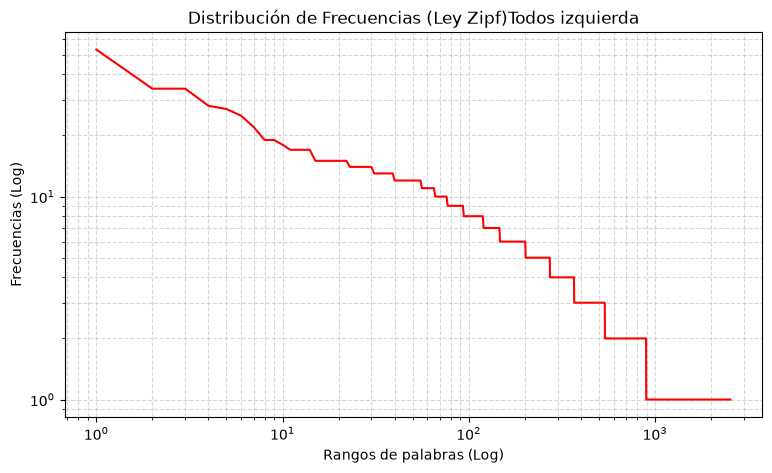

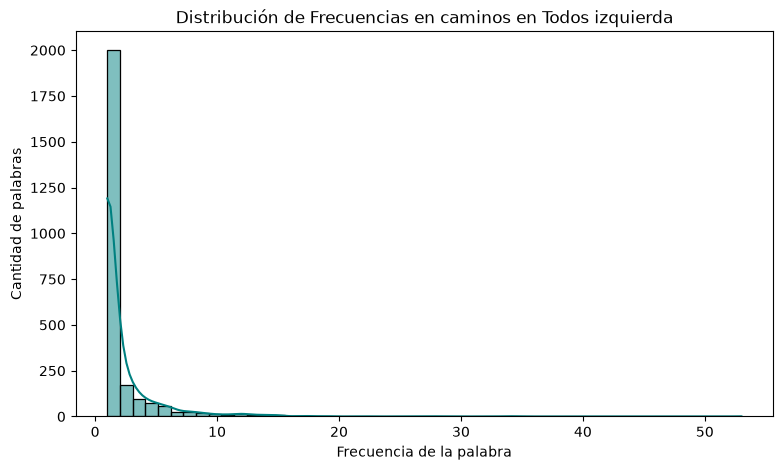

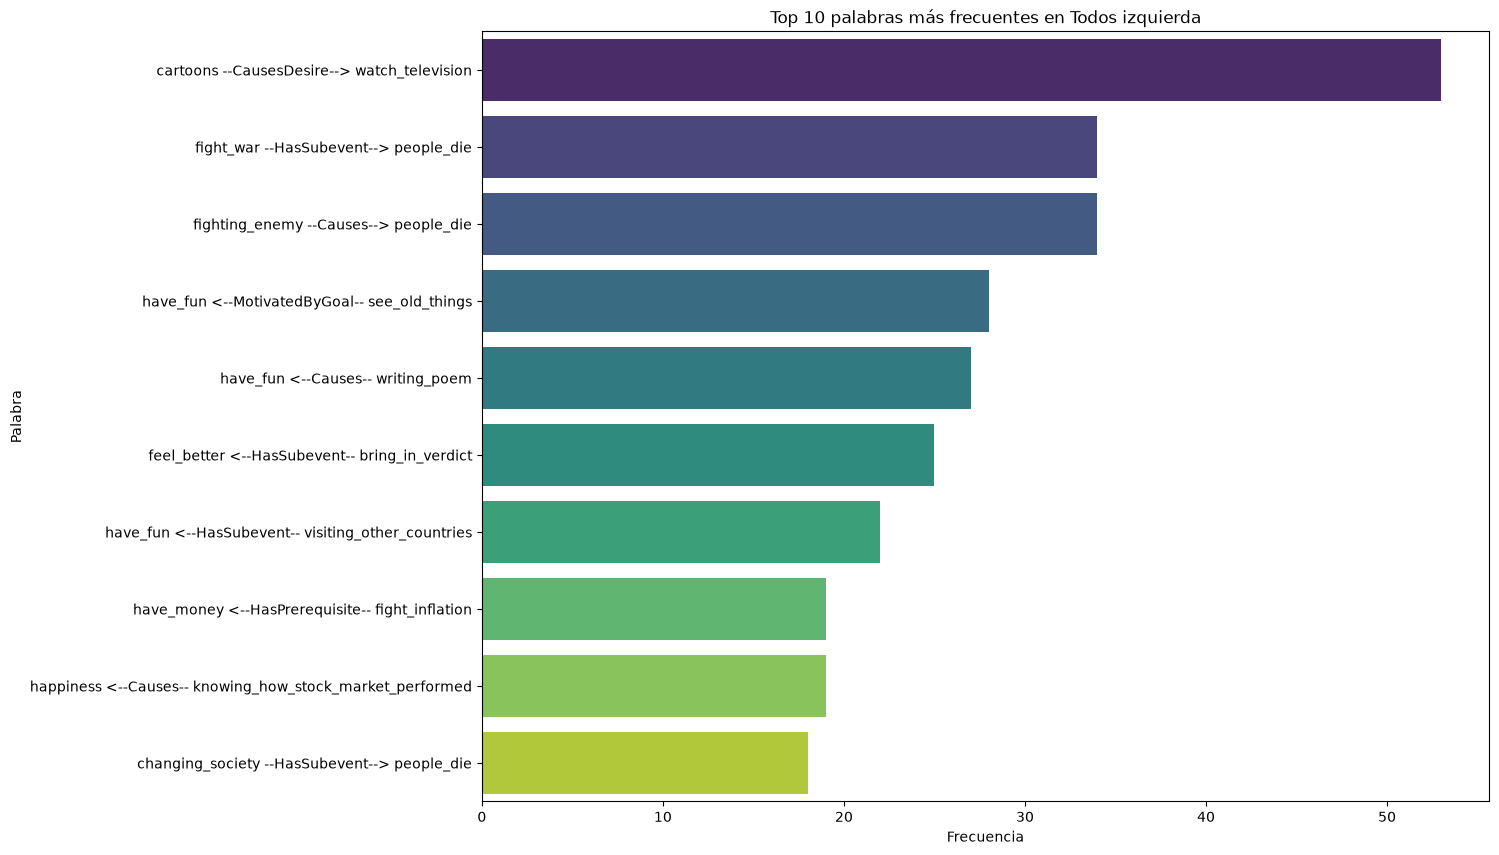

In [55]:
top10VecinosI = graficador(datos = conteoVecionsIzquierda, idioma= 'Todos izquierda', top_n=10)

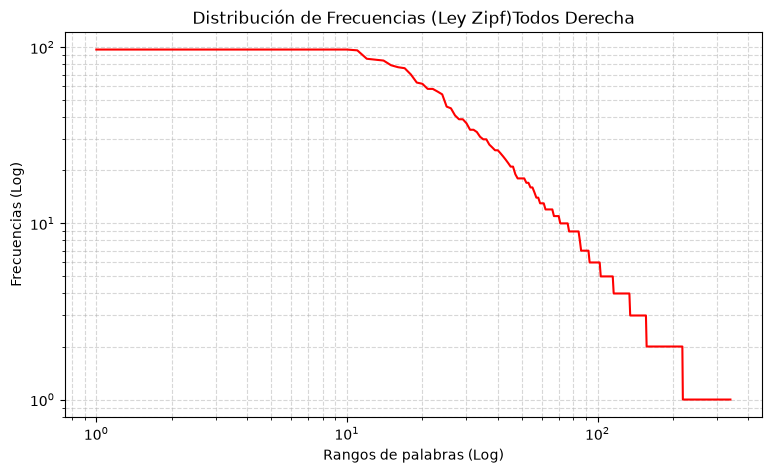

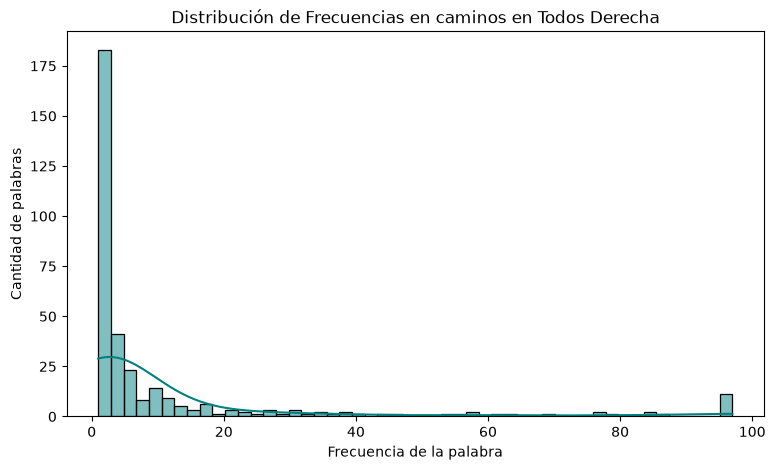

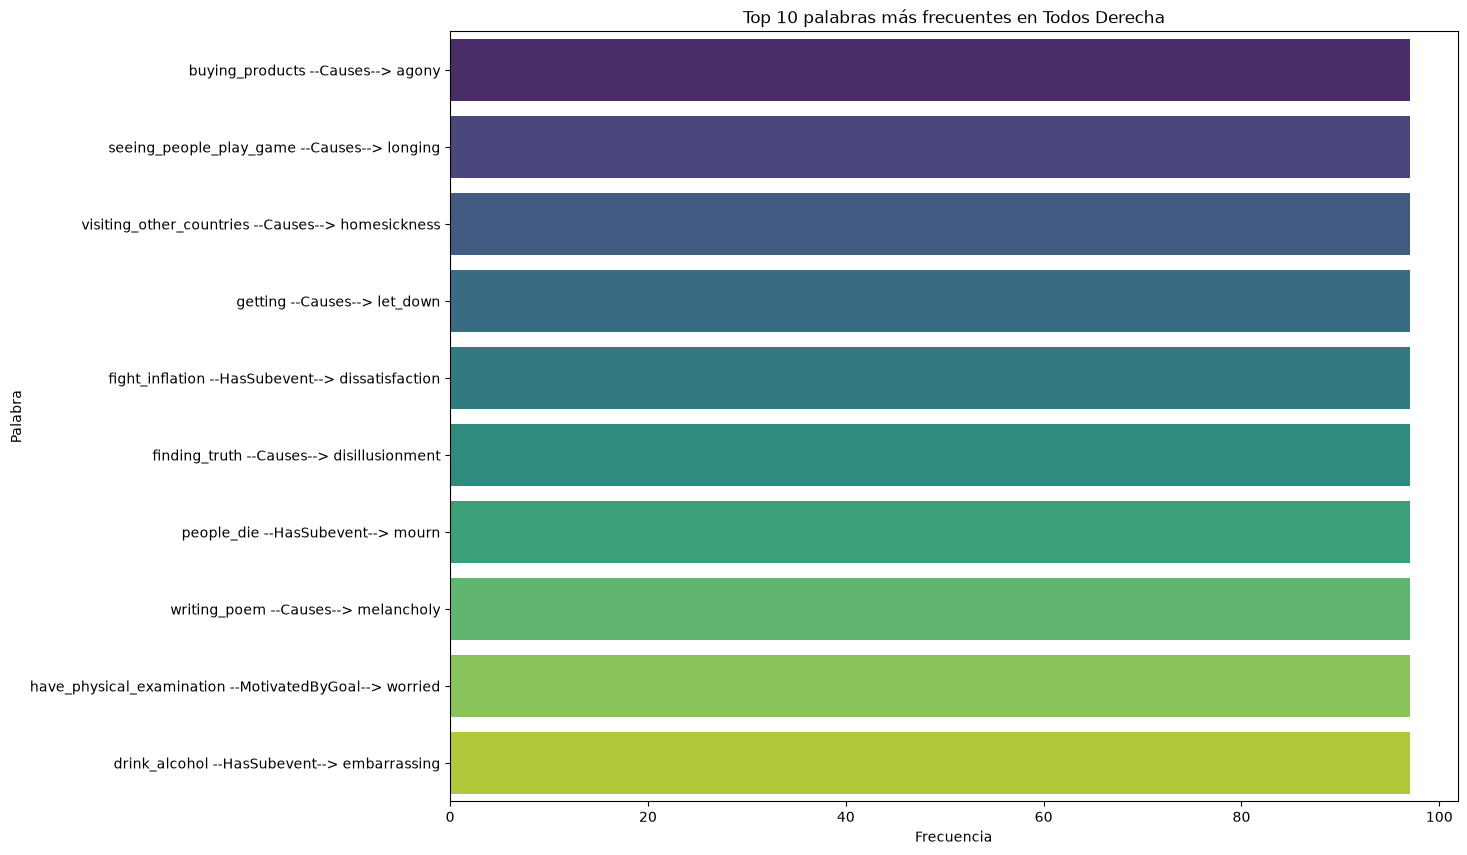

In [56]:
top10VecinosD = graficador(datos = conteoVecionsDerecha, idioma= 'Todos Derecha', top_n=10)

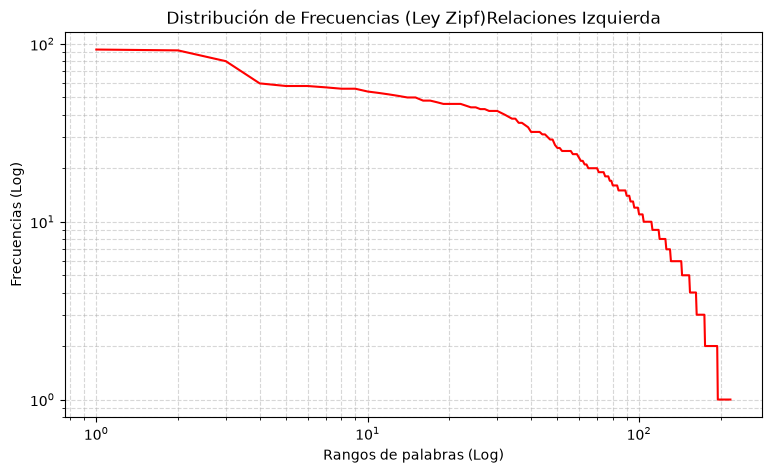

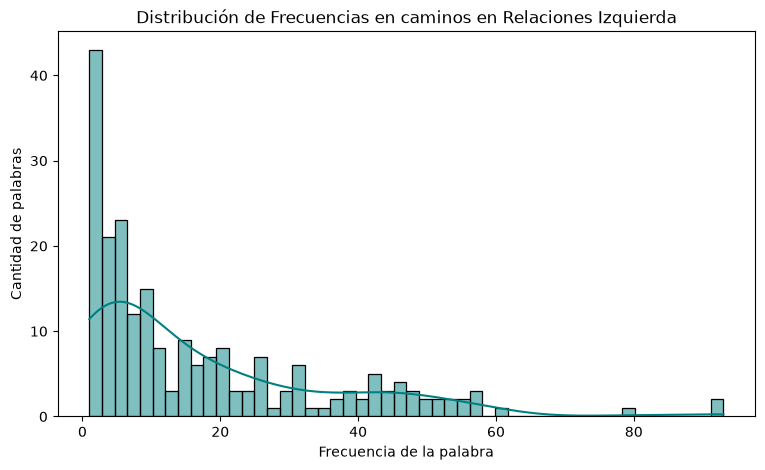

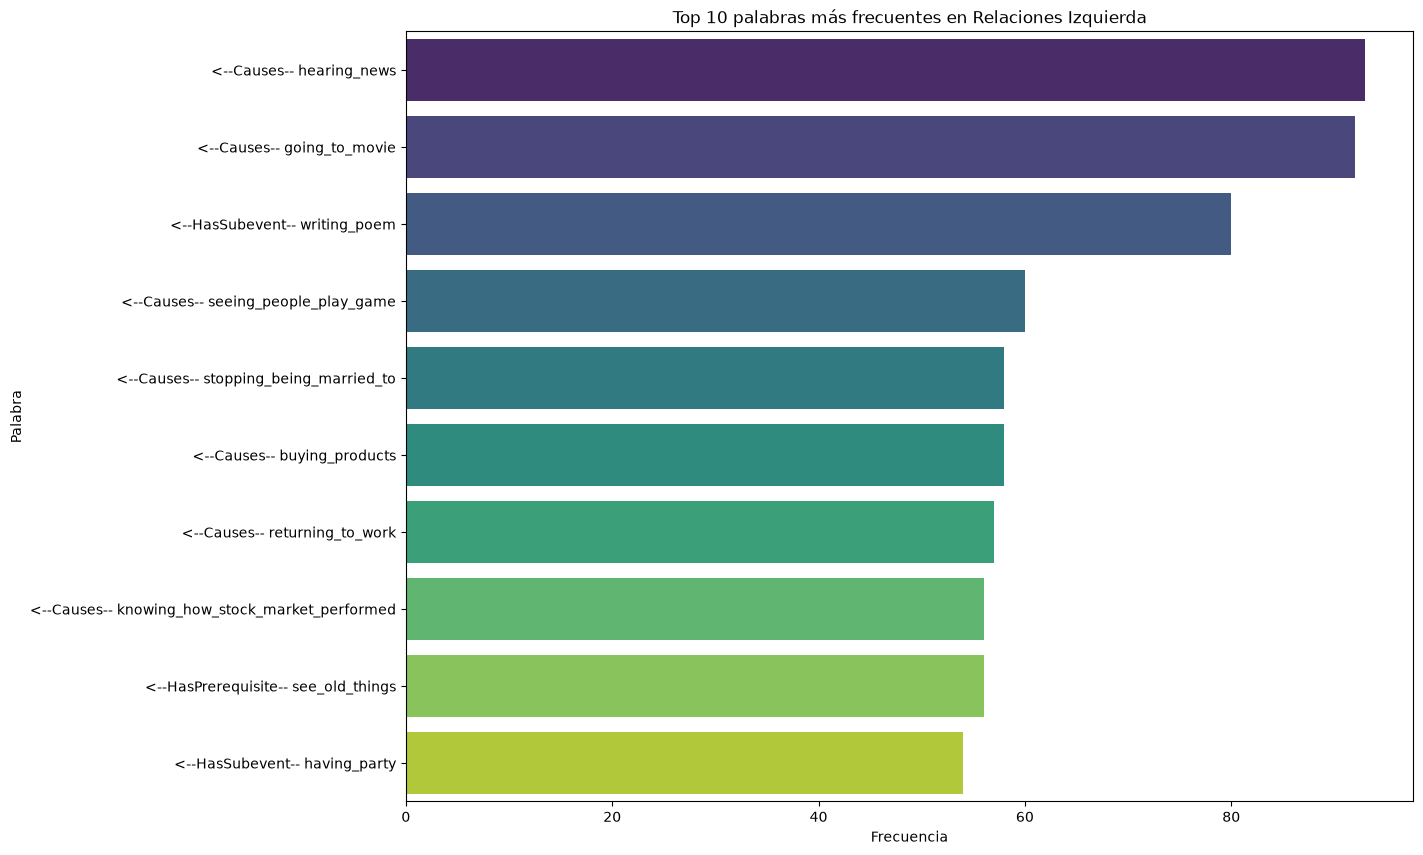

In [57]:
top10RelacionesI = graficador(datos= conteoRelacionesIzquierda, idioma = 'Relaciones Izquierda', top_n=10)

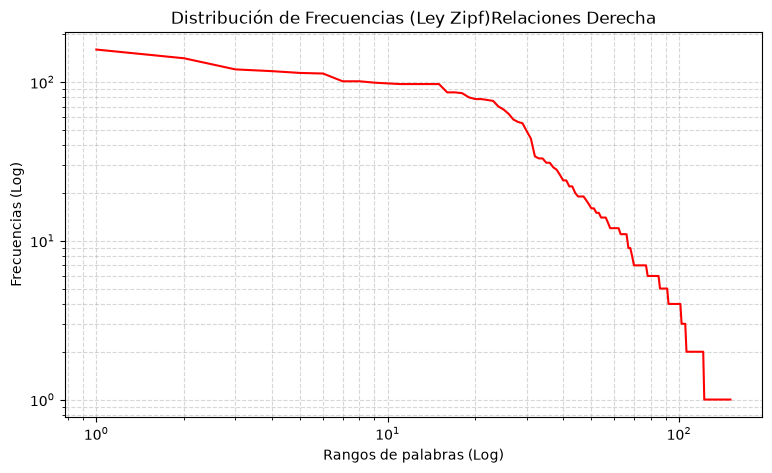

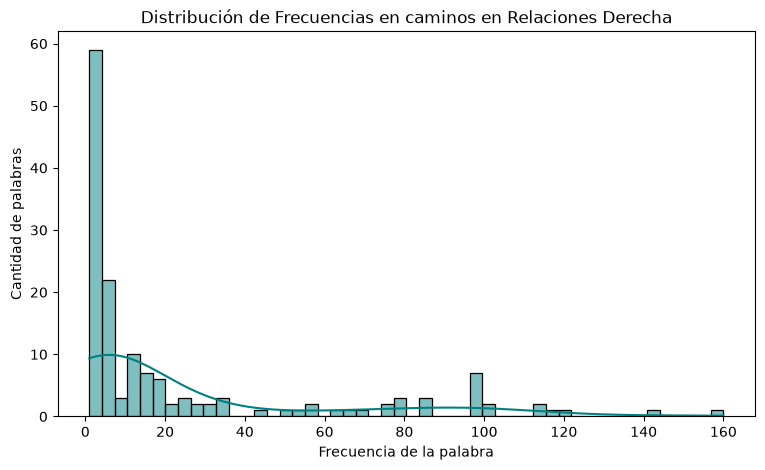

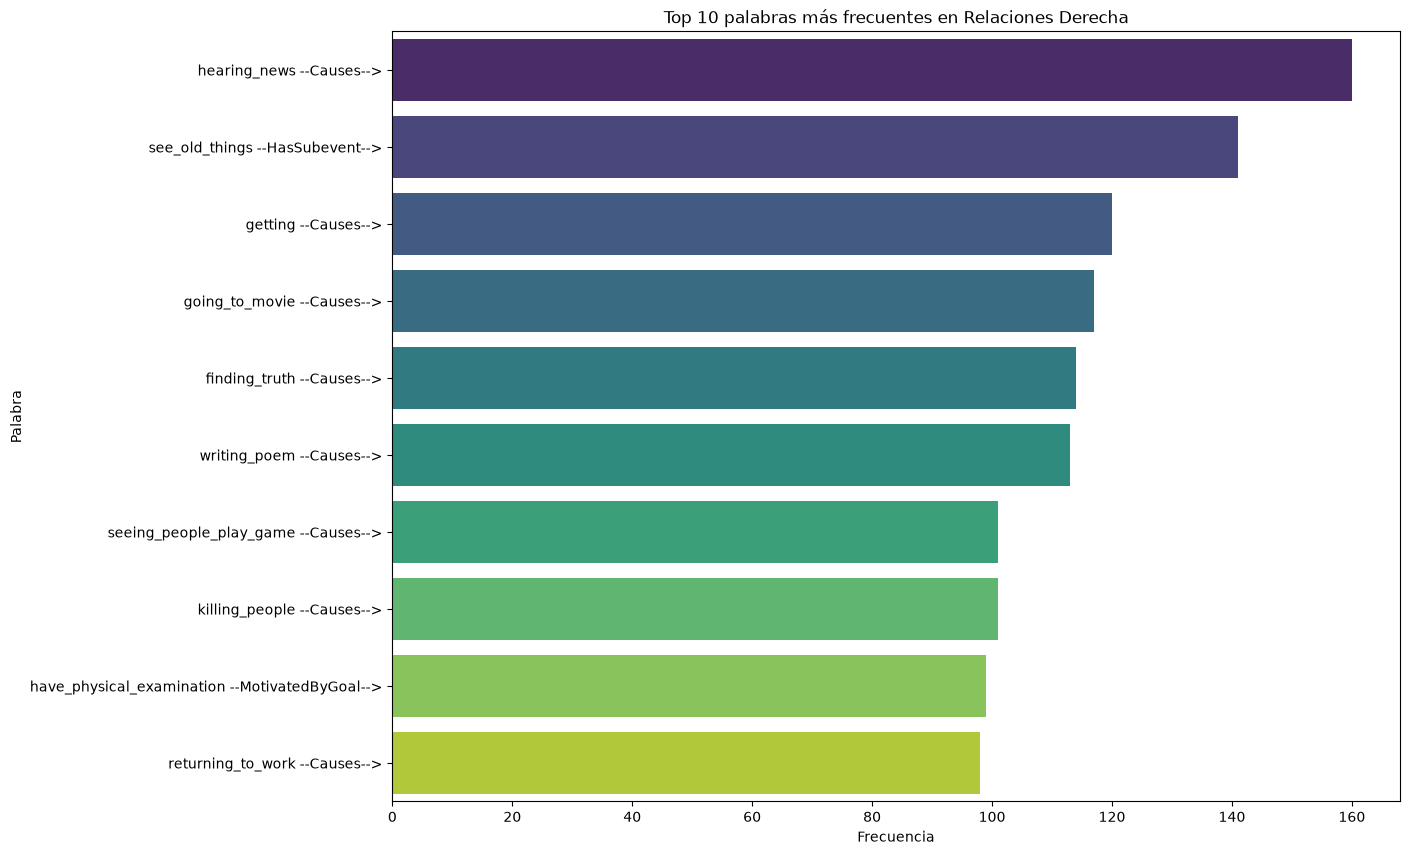

In [58]:
top10RelacionesD = graficador(datos= conteoRelacionesDerecha, idioma= 'Relaciones Derecha', top_n=10)

In [23]:
conteoVecions

Counter({('fighting_enemy',
          '--Causes-->',
          'people_die',
          '--HasSubevent-->',
          'mourn'): 34,
         ('fight_war',
          '--HasSubevent-->',
          'people_die',
          '--HasSubevent-->',
          'mourn'): 33,
         ('have_fun',
          '<--HasSubevent--',
          'visiting_other_countries',
          '--Causes-->',
          'homesickness'): 22,
         ('have_fun',
          '<--Causes--',
          'writing_poem',
          '--Causes-->',
          'melancholy'): 20,
         ('have_money',
          '<--HasPrerequisite--',
          'fight_inflation',
          '--HasSubevent-->',
          'dissatisfaction'): 19,
         ('changing_society',
          '--HasSubevent-->',
          'people_die',
          '--HasSubevent-->',
          'mourn'): 18,
         ('feel_better',
          '<--HasSubevent--',
          'bring_in_verdict',
          '--HasPrerequisite-->',
          'guilty'): 18,
         ('have_fun',
          

In [24]:
conteoVecionsDerecha

Counter({('buying_products', '--Causes-->', 'agony'): 97,
         ('seeing_people_play_game', '--Causes-->', 'longing'): 97,
         ('visiting_other_countries', '--Causes-->', 'homesickness'): 97,
         ('getting', '--Causes-->', 'let_down'): 97,
         ('fight_inflation', '--HasSubevent-->', 'dissatisfaction'): 97,
         ('finding_truth', '--Causes-->', 'disillusionment'): 97,
         ('people_die', '--HasSubevent-->', 'mourn'): 97,
         ('writing_poem', '--Causes-->', 'melancholy'): 97,
         ('have_physical_examination', '--MotivatedByGoal-->', 'worried'): 97,
         ('drink_alcohol', '--HasSubevent-->', 'embarrassing'): 97,
         ('hearing_news', '--Causes-->', 'dismay'): 96,
         ('returning_to_work', '--Causes-->', 'malaise'): 86,
         ('drink_alcohol', '<--CausesDesire--', 'desperation'): 85,
         ('having_party', '--Causes-->', 'tiring'): 84,
         ('see_old_things', '--HasSubevent-->', 'pity'): 79,
         ('bring_in_verdict', '--HasPrer

In [25]:
conteoVecionsIzquierda

Counter({('cartoons', '--CausesDesire-->', 'watch_television'): 53,
         ('fight_war', '--HasSubevent-->', 'people_die'): 34,
         ('fighting_enemy', '--Causes-->', 'people_die'): 34,
         ('have_fun', '<--MotivatedByGoal--', 'see_old_things'): 28,
         ('have_fun', '<--Causes--', 'writing_poem'): 27,
         ('feel_better', '<--HasSubevent--', 'bring_in_verdict'): 25,
         ('have_fun', '<--HasSubevent--', 'visiting_other_countries'): 22,
         ('have_money', '<--HasPrerequisite--', 'fight_inflation'): 19,
         ('happiness',
          '<--Causes--',
          'knowing_how_stock_market_performed'): 19,
         ('changing_society', '--HasSubevent-->', 'people_die'): 18,
         ('happiness', '<--Causes--', 'stopping_being_married_to'): 17,
         ('get_bored', '<--HasSubevent--', 'seeing_people_play_game'): 17,
         ('seeing_new', '<--Causes--', 'going_to_movie'): 17,
         ('relax', '<--HasSubevent--', 'writing_poem'): 17,
         ('ability_to_hea

In [26]:
conteoRelacionesDerecha

Counter({('hearing_news', '--Causes-->'): 160,
         ('see_old_things', '--HasSubevent-->'): 141,
         ('getting', '--Causes-->'): 120,
         ('going_to_movie', '--Causes-->'): 117,
         ('finding_truth', '--Causes-->'): 114,
         ('writing_poem', '--Causes-->'): 113,
         ('seeing_people_play_game', '--Causes-->'): 101,
         ('killing_people', '--Causes-->'): 101,
         ('have_physical_examination', '--MotivatedByGoal-->'): 99,
         ('returning_to_work', '--Causes-->'): 98,
         ('buying_products', '--Causes-->'): 97,
         ('visiting_other_countries', '--Causes-->'): 97,
         ('fight_inflation', '--HasSubevent-->'): 97,
         ('people_die', '--HasSubevent-->'): 97,
         ('drink_alcohol', '--HasSubevent-->'): 97,
         ('having_party', '--Causes-->'): 86,
         ('determining_truth', '--Causes-->'): 86,
         ('drink_alcohol', '<--CausesDesire--'): 85,
         ('loving_else', '--Causes-->'): 80,
         ('commit_suicide', '-

In [27]:
conteoRelacionesIzquierda

Counter({('<--Causes--', 'hearing_news'): 93,
         ('<--Causes--', 'going_to_movie'): 92,
         ('<--HasSubevent--', 'writing_poem'): 80,
         ('<--Causes--', 'seeing_people_play_game'): 60,
         ('<--Causes--', 'stopping_being_married_to'): 58,
         ('<--Causes--', 'buying_products'): 58,
         ('<--Causes--', 'returning_to_work'): 57,
         ('<--Causes--', 'knowing_how_stock_market_performed'): 56,
         ('<--HasPrerequisite--', 'see_old_things'): 56,
         ('<--HasSubevent--', 'having_party'): 54,
         ('--CausesDesire-->', 'watch_television'): 53,
         ('--HasSubevent-->', 'people_die'): 52,
         ('<--HasSubevent--', 'getting'): 51,
         ('<--Causes--', 'killing_people'): 50,
         ('<--Causes--', 'getting'): 50,
         ('<--Causes--', 'visiting_other_countries'): 48,
         ('<--HasPrerequisite--', 'have_physical_examination'): 48,
         ('<--Causes--', 'finding_truth'): 47,
         ('<--HasPrerequisite--', 'fight_inflation

## Exploración de conjunto de datos de meta-análisis 

In [6]:
df.columns

Index(['Study ID', 'Study', 'Year', 'r', 'z', 'N', 'v', 'Appraisal', 'Emotion',
       'specific_region_if_present', 'country', 'female', 'age',
       'remarks_Emotion', 'remarks_Appraisal', 'remarks', 'Dissertation',
       'exp', 'included', 'context', 'sample', 'region',
       'used_appraisalTheories', 'definition_appraisals'],
      dtype='object')

In [111]:
len(df['Appraisal'].value_counts())

183